(lineage_tracing)=

# Lineage tracing

Cells that look alike can be heading for different fates. A single-cell transcriptome is a snapshot, so trajectory methods infer where a cell is heading from where it sits among other cells, and nothing in the snapshot shows what the cell became. Lineage tracing marks cells with a heritable barcode and profiles their descendants later: the cells that share a barcode form a clone, and the clone's later cells show which fates its earlier cells were heading for.

This page analyzes the in vitro experiment of @Weinreb_2020. Their LARRY barcodes (Lineage And RNA RecoverY) are random 28-base sequences in the 3' UTR of an enhanced green fluorescent protein gene, delivered by lentivirus and read with each cell's transcriptome. Mouse hematopoietic progenitors, sorted as Lin⁻Sca1⁺Kit⁺ (LSK) and Lin⁻Sca1⁻Kit⁺ cells, were barcoded and cultured for two days, in which they divided three times on average. Half of the cells were then sampled for single-cell RNA sequencing, and the rest were replated and sampled two and four days later, on days 4 and 6. A clone's cells on day 2 and on days 4 and 6 descend from one barcoded cell, so the later cells show which fates a day-2 cell's sisters took, the closest measure of where the day-2 cell itself was heading.

The page imports the authors' clones, measures their sizes on each day, finds which fates share clones, labels each day-2 progenitor by the fates that its clone took, and asks how well fate probabilities computed from expression alone predict those fates, the test that the authors used to benchmark such methods.

## Download the experiment

GEO series [GSE140802](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE140802) holds the in vitro experiment as sample GSM4185642: the cells' metadata, the clone matrix, the gene names and the expression matrix of 130,887 cells and 25,289 genes. The expression matrix holds normalized values rather than counts, and its 2.1 GB take most of the download time.

The example uses a temporary directory. Use a project directory instead if you want to keep the downloaded files and the store after closing the notebook. The downloads and the store take about 7 GB, so choose a directory on disk where the temporary directory is held in memory.

In [1]:
# Download and verify the published files.
import gzip
import hashlib
import shutil
from pathlib import Path
from tempfile import TemporaryDirectory
from urllib.request import urlopen

# Read the tables and the expression matrix, and score the predictions.
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.metrics import roc_auc_score

# Build the store and plot its results.
import cytearc
from cytearc.plotting import CellField, ColorScale
from cytearc.storage.count_matrix import CountMatrixPolicy

# Keep routine logs and progress bars out of the results.
cytearc.configure_output(level="WARNING", progress=False)

# Keep this example's downloads and store together.
work = TemporaryDirectory()
output_dir = Path(work.name)

Started: 2026-11-06T17:49:09.099082Z | Wall time: 3.564 s

In [2]:
# Pin the four GEO files so that a changed download cannot alter the example silently.
geo = (
    "https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM4185nnn/GSM4185642/suppl/"
    "GSM4185642_stateFate_inVitro_"
)
sources = {
    "metadata": (
        "metadata.txt.gz",
        "d98f67d01aa5d9aa3f8000466d6bf19bdb0596ecdc3eb7ef896b6f6ff49b55a2",
    ),
    "clones": (
        "clone_matrix.mtx.gz",
        "3ec9c54e9b1b53697f2a247609014c903e6670cc28a5cf0d8016810a101a7148",
    ),
    "genes": (
        "gene_names.txt.gz",
        "0e4513b828461b9ea1c48740a14686d417f06ff0137c4ae61a780a2c4ae0303d",
    ),
    "expression": (
        "normed_counts.mtx.gz",
        "f0736087e71f039baaa3d735f6fde87f391eb8df89c6a8223593e37ab48e2564",
    ),
}
paths = {}
for name, (suffix, expected_digest) in sources.items():
    path = output_dir / f"GSM4185642_stateFate_inVitro_{suffix}"

    # Copy the response in blocks without holding the file in memory.
    with urlopen(geo + suffix, timeout=60) as response, path.open("wb") as destination:
        shutil.copyfileobj(response, destination)

    # Reject a file whose contents differ from the verified source.
    with path.open("rb") as source:
        actual_digest = hashlib.file_digest(source, "sha256").hexdigest()
    if actual_digest != expected_digest:
        raise ValueError(f"Checksum mismatch for {path.name}")
    paths[name] = path

# Show the size of each completed download.
pd.Series(
    {name: path.stat().st_size / 1_000_000 for name, path in paths.items()},
    name="Downloaded MB",
).round(2)

metadata         2.22
clones           0.20
genes            0.07
expression    2065.70
Name: Downloaded MB, dtype: float64

Started: 2026-11-06T17:49:12.666102Z | Wall time: 48.279 s

## Build the store

The metadata holds one row per cell, in the order of the cells of both matrices: its inDrops library, cell barcode, day, sorted starting population, the authors' cell type annotation, culture well and position in the authors' SPRING layout. A barcode repeats across the 35 libraries, so name each cell by its library and barcode joined by `__`, as a merged store names cells.

In [3]:
# Read each cell's library, barcode, day, annotation and layout position.
metadata = pd.read_csv(paths["metadata"], sep="\t")

# Name each cell by its library and barcode, since barcodes repeat across libraries.
cell_ids = metadata["Library"] + "__" + metadata["Cell barcode"]
if not cell_ids.is_unique:
    raise ValueError("Two cells share a library and a barcode")

# Read the gene names, one per column of the expression matrix.
genes = pd.read_csv(paths["genes"], header=None)[0]

# Count the cells of each annotation on each day.
pd.crosstab(
    metadata["Cell type annotation"],
    metadata["Time point"].astype(int).rename("Day"),
    margins=True,
    margins_name="All",
)

Day,2,4,6,All
Cell type annotation,,,,
Baso,187,3247,6721,10155
Ccr7_DC,57,100,84,241
Eos,15,189,351,555
Erythroid,100,153,433,686
Lymphoid,144,583,130,857
Mast,40,579,1965,2584
Meg,97,632,1367,2096
Monocyte,950,7505,10727,19182
Neutrophil,1068,6721,14448,22237


Started: 2026-11-06T17:50:00.948969Z | Wall time: 0.341 s

Most day-2 cells are undifferentiated, and most mature types grow from day to day. CyteArc's Matrix Market reader reads counts, while this matrix holds normalized values, so read its 177 million entries with pandas, a chunk at a time, and write the store with `SparseToZarr`. The file lists its entries gene by gene, so gather them into a matrix with cells as rows before writing it.

In [4]:
# Read the matrix's dimensions, which follow its header comments.
with gzip.open(paths["expression"], "rt") as handle:
    header_lines = 0
    for line in handle:
        header_lines += 1
        if not line.startswith("%"):
            n_cells, n_genes, n_entries = map(int, line.split())
            break

# Check that the matrix holds the cells of the metadata and the listed genes.
if (n_cells, n_genes) != (len(metadata), len(genes)):
    raise ValueError("The matrix does not match the metadata and the gene names")

# Read the entries a chunk at a time into 32-bit positions and values.
rows = np.empty(n_entries, dtype=np.int32)
columns = np.empty(n_entries, dtype=np.int32)
values = np.empty(n_entries, dtype=np.float32)
position = 0
for chunk in pd.read_csv(
    paths["expression"],
    sep=" ",
    header=None,
    skiprows=header_lines,
    names=["cell", "gene", "value"],
    dtype={"cell": np.int32, "gene": np.int32, "value": np.float32},
    chunksize=10_000_000,
):
    end = position + len(chunk)
    rows[position:end] = chunk["cell"].to_numpy() - 1
    columns[position:end] = chunk["gene"].to_numpy() - 1
    values[position:end] = chunk["value"].to_numpy()
    position = end

# Check that the file held every entry that its header declares.
if position != n_entries:
    raise ValueError(f"Read {position} entries, but the header declares {n_entries}")

# Gather the entries into a matrix with cells as rows.
expression = sparse.csr_matrix((values, (rows, columns)), shape=(n_cells, n_genes))
del rows, columns, values

# Show the spread of the cells' totals.
totals = np.asarray(expression.sum(axis=1)).ravel()
pd.Series(totals, name="Cell total").describe().round(2)

count    130887.00
mean       2878.75
std           0.00
min        2878.75
25%        2878.75
50%        2878.75
75%        2878.75
max        2878.75
Name: Cell total, dtype: float64

Started: 2026-11-06T17:50:01.292610Z | Wall time: 75.892 s

Every cell's values sum to 2,878.75, so the values are each cell's counts scaled to one common total. `values="normalized"` records them as such, so the store refuses steps that need counts, and CyteArc would decide the same from the values if the argument were left out. The import's default count layout needs a little more memory than the 6 GiB budget of the machine that executes this page, so pass the smaller layout that the import names when the default does not fit; with more memory, leave `policy` out.

In [5]:
# Write the store, then release the matrix that it copied.
store_path = output_dir / "larry_in_vitro.zarr"
cytearc.SparseToZarr(
    expression,
    str(store_path),
    cell_ids=cell_ids.to_numpy(),
    feature_ids=genes.to_numpy(),
    policy=CountMatrixPolicy(unitBytes=500_000_000, chunkBytes=50_000_000),
    values="normalized",
).dump()
del expression

# Open the store.
ds = cytearc.DataStore(str(store_path), default_assay="RNA")

# Record each cell's metadata under short column names, in the store's cell order.
ds.cells.insert("library", metadata["Library"].to_numpy())
ds.cells.insert("starting_population", metadata["Starting population"].to_numpy())
ds.cells.insert("cell_type", metadata["Cell type annotation"].to_numpy())
ds.cells.insert("day", metadata["Time point"].astype(int).to_numpy())
ds.cells.insert("well", metadata["Well"].to_numpy())

# Keep the SPRING layout as the two columns that an embedding plot reads.
ds.cells.insert("SPRING1", metadata["SPRING-x"].to_numpy())
ds.cells.insert("SPRING2", metadata["SPRING-y"].to_numpy())
ds

DataStore has 130887 (130887) cells with 1 assays: RNA
   Cell metadata:
            'I', 'ids', 'names', 'RNA_nCounts', 'RNA_nFeatures', 
            'RNA_percentMito', 'RNA_percentRibo', 'SPRING1', 'SPRING2', 'cell_type', 
            'day', 'library', 'starting_population', 'well'
   RNA assay has 25289 features and following metadata:
            'I', 'ids', 'names', 'dropOuts', 'nCells'

Started: 2026-11-06T17:51:17.188872Z | Wall time: 27.293 s

The SPRING layout draws the authors' graph of the cells' expression. Draw the cells on it by annotation and by day.

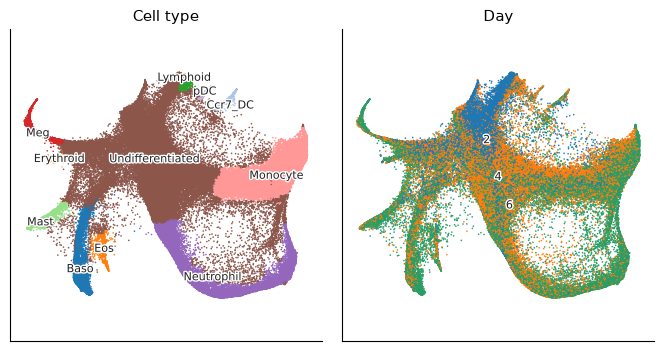

Started: 2026-11-06T17:51:44.485535Z | Wall time: 2.519 s

In [6]:
# Draw the cells on the authors' layout by annotation and by day.
ds.plots.embedding(
    layout_key="SPRING",
    color_by=[
        CellField("cell_type", kind="categorical", label="Cell type"),
        CellField("day", kind="categorical", label="Day"),
    ],
    n_columns=2,
    legend_loc="on_data",
)

Day-2 cells sit at the top of the layout, among the undifferentiated progenitors, and day-4 and day-6 cells fill the branches of the mature types: neutrophils and monocytes on the right, basophils, eosinophils and mast cells at the bottom left, megakaryocytes and erythroid cells on the left, and dendritic and lymphoid cells at the top.

## Import the clones

The clone matrix holds a 1 where a cell belongs to a clone, with its cells in the order of the metadata, so `import_clones` reads the metadata beside the matrix as its list of cells. `columns` names the two columns that make each cell's ID.

In [7]:
# Freeze every cell of the store as the cells that the clones join.
cells = ds.snapshot_cell_selection("I")

# Import the clones; the metadata beside the matrix names their cells.
clones = ds.clones.import_clones(
    paths["clones"],
    cell_selection=cells,
    columns={"cell": ["Library", "Cell barcode"]},
)

# Check that every cell of the clone matrix joined a cell of the store.
joined = ds.artifacts.inspect(clones).diagnostics
pd.Series(
    {
        "Cells in the clone matrix": joined["fileBarcodes"],
        "Cells that name no cell of the store": joined["unmatchedBarcodes"],
        "Cells with a clone": joined["cellsWithClone"],
    },
    name="Clone import",
)

Cells in the clone matrix               130887
Cells that name no cell of the store         0
Cells with a clone                       49302
Name: Clone import, dtype: int64

Started: 2026-11-06T17:51:47.007518Z | Wall time: 0.863 s

In [8]:
# Summarize the clones by their sizes.
table = ds.clones.load_clones(clones)
pd.Series(
    {
        "Clones": len(table.clones),
        "Smallest clone": table.clones["n_cells"].min(),
        "Median clone": table.clones["n_cells"].median(),
        "Largest clone": table.clones["n_cells"].max(),
    },
    name="Cells",
    dtype=object,
)

Clones            5864
Smallest clone       2
Median clone       4.0
Largest clone      177
Name: Cells, dtype: object

Started: 2026-11-06T17:51:47.872857Z | Wall time: 0.080 s

All 130,887 cells of the clone matrix joined the store, and 49,302 of them, 38%, belong to one of 5,864 clones of 2 to 177 cells. The deposit lists only clones of two or more cells, so a cell without a clone may be the only sampled cell of its clone.

## Clone sizes on each day

A clone's cells on one day are a sample of its descendants on that day. Draw the number of clones of each size on each day, and the largest clones by day.

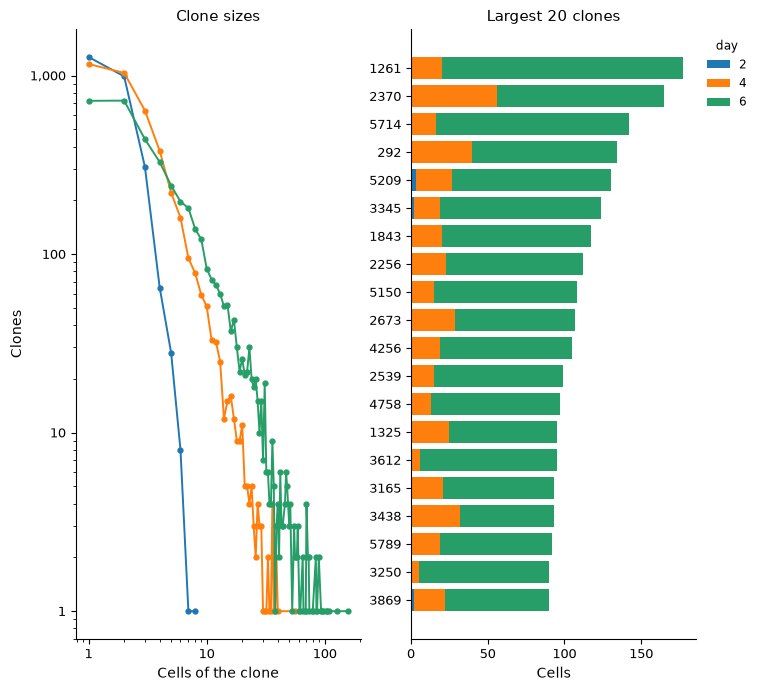

Started: 2026-11-06T17:51:47.955108Z | Wall time: 0.723 s

In [9]:
# Draw the number of clones of each size on each day, and the largest clones by day.
ds.plots.clone_abundance(clones, group_by="day")

In [10]:
# Read each cell's ID, annotation and day in the store's order.
ids = ds.cells.fetch("ids", key="I")
cell_type = ds.cells.fetch("cell_type", key="I")
day = ds.cells.fetch("day", key="I")
cell_info = pd.DataFrame({"cell_type": cell_type, "day": day}, index=ids)

# Count each clone's cells on each day.
clone_cells = table.cells.dropna(subset=["clone"]).join(cell_info)
day_sizes = clone_cells.groupby(["day", "clone"], observed=True).size()

# Summarize each day's clones by their sizes on that day.
by_day = day_sizes.groupby(level="day")
small = (day_sizes <= 2).groupby(level="day").mean() * 100
pd.DataFrame(
    {"Clones": by_day.size(), "Of one or two cells (%)": small, "Largest": by_day.max()}
).round(1).rename_axis("Day")

,Clones,Of one or two cells (%),Largest
Day,,,
2,2672,84.6,8
4,4101,53.5,56
6,3956,36.6,157


Started: 2026-11-06T17:51:48.680437Z | Wall time: 0.114 s

On day 2, 85% of the clones hold one or two sampled cells, and the largest holds 8. The clones grow from day to day, to 157 cells on day 6, and the largest clones are mostly day-6 cells. A clone with cells on day 2 and on a later day links a day-2 cell's state to the fates of its sisters.

## Fates that share clones

Fate coupling measures how often two cell types share clones. Measure it among the day-6 cells of the ten mature types with the default index, the cosine of each type's share of each clone, which counts every clone once whatever its size. Draw the couplings in the order of their tree, which joins first the types that couple most strongly.

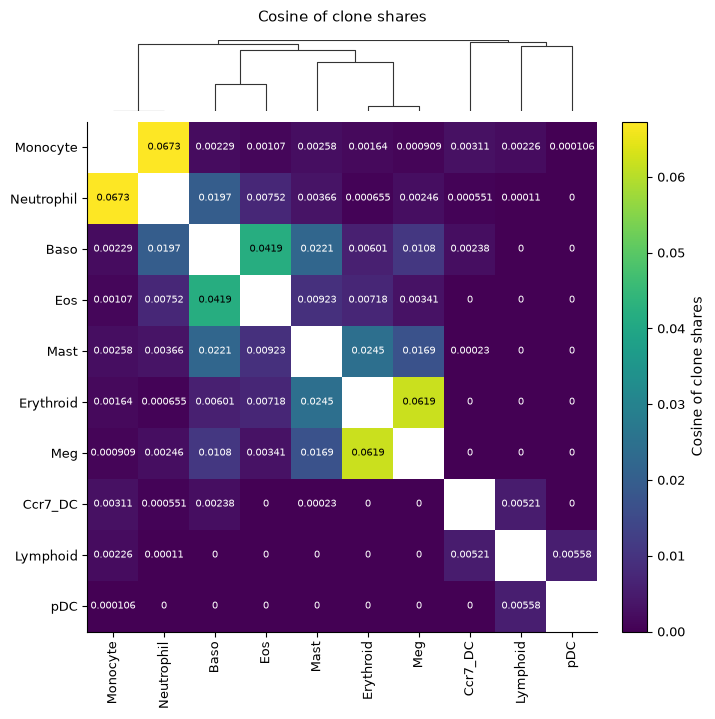

Started: 2026-11-06T17:51:48.796699Z | Wall time: 3.812 s

In [11]:
# Mark the day-6 cells of the mature types.
ds.cells.insert("day6_mature", (day == 6) & (cell_type != "Undifferentiated"))

# Measure how strongly each pair of mature types shares clones on day 6.
coupling = ds.clones.coupling(
    clones,
    group_by="cell_type",
    cell_selection=ds.snapshot_cell_selection("day6_mature"),
)
ds.plots.clone_coupling(coupling, value="coupling")

In [12]:
# Show the most coupled pairs beside the couplings of shuffled labels.
top_pairs = coupling.pairs.sort_values("coupling", ascending=False).head(6)
top_pairs.set_index(["group_1", "group_2"]).round(3)

coupling  null_mean  null_sd  z_score
group_1   group_2                                          
Monocyte  Neutrophil     0.067      0.217    0.007  -20.483
Erythroid Meg            0.062      0.054    0.007    1.217
Baso      Eos            0.042      0.024    0.002    8.035
Erythroid Mast           0.024      0.054    0.006   -5.214
Baso      Mast           0.022      0.117    0.006  -15.993
          Neutrophil     0.020      0.199    0.007  -24.595

Started: 2026-11-06T17:51:52.611102Z | Wall time: 0.012 s

In [13]:
# Count the mature types among each clone's day-6 cells.
day6_types = (
    clone_cells.query("day == 6 and cell_type != 'Undifferentiated'")
    .groupby("clone", observed=True)["cell_type"]
    .agg(["size", "nunique"])
    .query("size >= 2")
)

# Count the pairs above their null, and the clones that hold one mature type.
pd.Series(
    {
        "Pairs of mature types": len(coupling.pairs),
        "Pairs that couple more than their null": int(
            (coupling.pairs["z_score"] > 0).sum()
        ),
        "Clones of two or more day-6 mature cells": len(day6_types),
        "Clones of one mature type": int((day6_types["nunique"] == 1).sum()),
    },
    name="Count",
)

Pairs of mature types                         45
Pairs that couple more than their null         2
Clones of two or more day-6 mature cells    2055
Clones of one mature type                   1455
Name: Count, dtype: int64

Started: 2026-11-06T17:51:52.625707Z | Wall time: 0.022 s

Neutrophils and monocytes couple most strongly, then erythroid cells and megakaryocytes, then basophils and eosinophils, and the tree joins the fates in three branches: neutrophils with monocytes; basophils, eosinophils, mast cells, erythroid cells and megakaryocytes; and the dendritic and lymphoid cells. @Weinreb_2020 found that the clones that cell types share in culture follow how close the types are in expression (r = 0.93), and that hierarchies built from either differ only in where mast cells branch.

Only basophils with eosinophils and erythroid cells with megakaryocytes couple more than their null, which shuffles the types of the cells and so spreads each clone over the types at random. Most clones commit to one type by day 6, 1,455 of the 2,055 with two or more day-6 mature cells, so most pairs, neutrophils with monocytes among them, share fewer clones than shuffled types would give them.

## Fate bias of day-2 progenitors

A day-2 progenitor's clone-mates on days 4 and 6 show which fates its clone took. `fate_bias` gives each early cell the share of its clone's late cells in each fate and its dominant fate, the fate that holds the most of them. Take the undifferentiated day-2 cells as the early cells, and the day-4 and day-6 cells of the mature types as the late cells, whose types are the fates.

In [14]:
# Mark the day-2 progenitors and the later cells of the mature types.
ds.cells.insert("day2_progenitor", (day == 2) & (cell_type == "Undifferentiated"))
ds.cells.insert("later_mature", (day > 2) & (cell_type != "Undifferentiated"))

# Label each progenitor by the fates of its clone's later cells.
bias = ds.clones.fate_bias(
    clones,
    group_by="cell_type",
    early=ds.snapshot_cell_selection("day2_progenitor"),
    late=ds.snapshot_cell_selection("later_mature"),
)
fates = ds.clones.load_fate_bias(bias)

# Count the progenitors that the dominant fates leave out.
traced = ds.artifacts.inspect(bias).diagnostics
pd.Series(
    {
        "Day-2 progenitors": len(fates.cells),
        "With a clone": int(fates.cells["clone"].notna().sum()),
        "Clone without later mature cells": traced["earlyCellsWithoutLateCells"],
        "Clone's later cells tie between fates": traced["earlyCellsWithTiedFates"],
        "With a dominant fate": int(fates.cells["fate"].notna().sum()),
    },
    name="Cells",
)

Day-2 progenitors                        25575
With a clone                              4199
Clone without later mature cells          2219
Clone's later cells tie between fates       59
With a dominant fate                      1921
Name: Cells, dtype: int64

Started: 2026-11-06T17:51:52.650006Z | Wall time: 1.029 s

In [15]:
# Count the progenitors by their clone's dominant fate.
dominant = fates.cells["fate"].value_counts()
dominant.rename_axis("Dominant fate").rename("Day-2 progenitors")

Dominant fate
Neutrophil    730
Monocyte      632
Baso          259
Meg           115
Lymphoid       87
Mast           45
Erythroid      20
Eos            15
Ccr7_DC        11
pDC             7
Name: Day-2 progenitors, dtype: int64

Started: 2026-11-06T17:51:53.681929Z | Wall time: 0.008 s

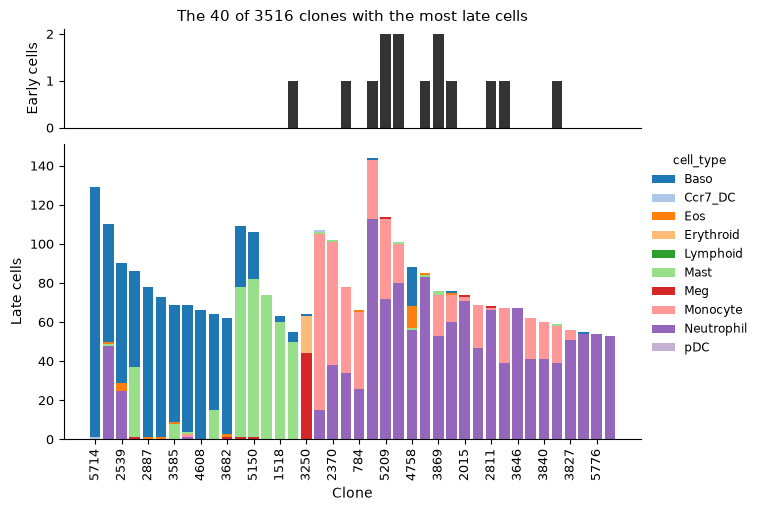

Started: 2026-11-06T17:51:53.692440Z | Wall time: 0.901 s

In [16]:
# Draw the late cells of the clones with the most late cells, by fate.
ds.plots.clone_fate_bias(bias)

Of the 25,575 day-2 progenitors, 4,199 have a clone, and 1,921 of them have a clone whose later mature cells have one dominant fate. Neutrophils or monocytes dominate the clones of 1,362 of those 1,921 progenitors, 71%. Among the clones with the most late cells, many mix two types, mostly neutrophils with monocytes or basophils with mast cells.

## Fate probabilities from expression

A fate map computed from expression alone predicts the same outcomes without a barcode. Build the neighbour graph with the RNA recipe. Passing the frozen cells keeps every cell that the authors kept, and the recipe selects highly variable genes, normalizes each cell to a common total, which turns values already scaled to one total into the values that the counts would give, and takes logs, reduces the genes with PCA and connects each cell to its nearest neighbours; this page needs no cell-cycle scores, UMAP, clusters, doublet scores or markers.

In [17]:
# Build the neighbour graph of every cell from its expression.
run = ds.pipeline.rna(
    label="larry",
    cells=cells,
    cell_cycle=False,
    umap=False,
    leiden=False,
    doublets=False,
    markers=False,
)

Started: 2026-11-06T17:51:54.596026Z | Wall time: 88.227 s

Pseudotime orders the graph from source cells to sink cells by population balance analysis [@Weinreb_2018], and fate probabilities give each cell the chance that a walk along the graph, moving mostly forward in pseudotime, reaches each sink first, as [](fate_mapping.ipynb) explains. Take the day-2 progenitors as the source, sharing a total weight of -1, and the cells of the ten mature types as the sinks, sharing +1.

In [18]:
# Weigh the day-2 progenitors as the source and the mature cells as the sinks.
mature_types = sorted(set(cell_type) - {"Undifferentiated"})
source = (cell_type == "Undifferentiated") & (day == 2)
sink = np.isin(cell_type, mature_types)
source_sink_vector = np.zeros(len(cell_type), dtype=float)
source_sink_vector[source] = -1.0 / source.sum()
source_sink_vector[sink] = 1.0 / sink.sum()

# Order the graph from the progenitors to the mature types.
graph = run["connectivity_map"]
pseudotime = ds.trajectory.pseudotime(graph, ss_vec=source_sink_vector)

# Compute each cell's probability of reaching each mature type.
type_labels = ds.snapshot_cluster_labels(
    "cell_type", cell_selection=run["analysis_cell_selection"]
)
fate_map = ds.trajectory.fate(pseudotime, type_labels, sinks=mature_types)
probabilities = ds.trajectory.load_fate(fate_map)

# Label the probabilities of the scored cells by fate.
predicted = pd.DataFrame(
    probabilities.values,
    columns=[str(label) for label in probabilities.sink_labels],
    index=ids,
)[probabilities.valid]

# Count the cells of the graph and the cells with probabilities.
pd.Series(
    {"Graph cells": len(probabilities.valid), "Scored cells": len(predicted)},
    name="Cells",
)

Graph cells     130887
Scored cells    130887
Name: Cells, dtype: int64

Started: 2026-11-06T17:53:22.826093Z | Wall time: 83.192 s

Every cell is in one connected graph and has probabilities.

## Score the predictions against the clones

Neutrophils or monocytes dominate most traced clones, and @Weinreb_2020 benchmarked fate prediction methods on the choice between them. Give each progenitor its predicted neutrophil share, its probability of reaching neutrophils over its probability of reaching neutrophils or monocytes, and its traced share, the neutrophils among its clone's later neutrophils and monocytes. Draw both for the progenitors whose clones went mostly to neutrophils or to monocytes.

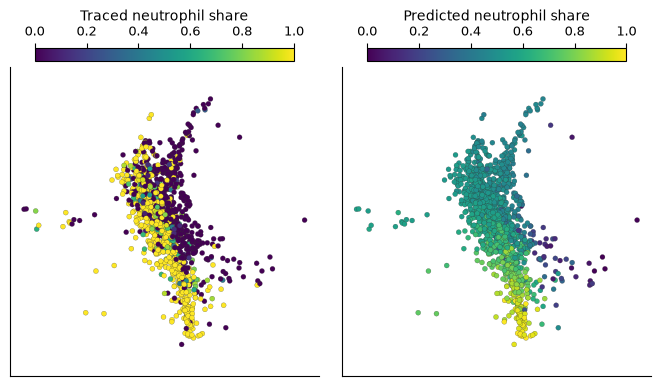

Started: 2026-11-06T17:54:46.020521Z | Wall time: 15.362 s

In [19]:
# Give each progenitor its predicted and its traced neutrophil share.
predicted_share = predicted["Neutrophil"] / (
    predicted["Neutrophil"] + predicted["Monocyte"]
)
traced_share = fates.fractions["Neutrophil"] / (
    fates.fractions["Neutrophil"] + fates.fractions["Monocyte"]
)
ds.cells.insert("predicted_neutrophil_share", predicted_share.reindex(ids).to_numpy())
ds.cells.insert("traced_neutrophil_share", traced_share.reindex(ids).to_numpy())

# Mark the progenitors whose clones went mostly to neutrophils or to monocytes.
outcome = fates.cells["fate"].isin(["Neutrophil", "Monocyte"])
ds.cells.insert(
    "neutrophil_or_monocyte", np.isin(ids, fates.cells.index[outcome.to_numpy()])
)

# Draw both shares of those progenitors on one scale.
ds.plots.embedding(
    layout_key="SPRING",
    color_by=[
        CellField(
            "traced_neutrophil_share",
            kind="continuous",
            label="Traced neutrophil share",
        ),
        CellField(
            "predicted_neutrophil_share",
            kind="continuous",
            label="Predicted neutrophil share",
        ),
    ],
    subset_by="neutrophil_or_monocyte",
    color_scale=ColorScale(scope="shared", vmin=0, vmax=1),
    n_columns=2,
)

Most traced shares are 0 or 1, since most clones went to one of the two types. At the top of the layout, the progenitors of neutrophil clones and of monocyte clones sit side by side, and the predicted shares there stay near one half. The predictions move toward 1 only for progenitors further down, toward the neutrophils, and toward 0 for the few on the right, toward the monocytes.

Score the predictions by clone, since a clone's progenitors share one traced outcome: average the predicted shares of each clone's progenitors, and measure how well the averages separate the clones that went mostly to neutrophils from those that went mostly to monocytes by the area under the ROC curve (AUROC), 0.5 for chance and 1 for a perfect separation. Resample the clones for a 95% interval.

In [20]:
# Pair each scored progenitor's predicted share with its clone and dominant fate.
scored = fates.cells[outcome].join(predicted_share.rename("predicted"), how="inner")
scored["neutrophil"] = scored["fate"] == "Neutrophil"


# Score how well the mean predicted shares of clones separate neutrophil clones
# from monocyte clones, with a 95% interval from clones drawn with replacement.
def clone_auroc(progenitors: pd.DataFrame) -> pd.Series:
    grouped = progenitors.groupby("clone", observed=True)[["neutrophil", "predicted"]]
    by_clone = grouped.mean()
    neutrophil = by_clone["neutrophil"].to_numpy() == 1
    share = by_clone["predicted"].to_numpy()
    samples = np.random.default_rng(0).integers(0, len(share), (2_000, len(share)))
    draws = [roc_auc_score(neutrophil[sample], share[sample]) for sample in samples]
    return pd.Series(
        {
            "Day-2 progenitors": len(progenitors),
            "Clones": len(share),
            "AUROC": round(roc_auc_score(neutrophil, share), 3),
            "Lower 95%": round(np.quantile(draws, 0.025), 3),
            "Upper 95%": round(np.quantile(draws, 0.975), 3),
        },
        dtype=object,
    )


# Score every progenitor of a neutrophil or monocyte clone.
clone_auroc(scored).rename("Neutrophil or monocyte clones")

Day-2 progenitors     1362
Clones                 916
AUROC                0.779
Lower 95%             0.75
Upper 95%            0.809
Name: Neutrophil or monocyte clones, dtype: object

Started: 2026-11-06T17:55:01.385811Z | Wall time: 5.220 s

Progenitors early in pseudotime sit closer to the source and further from every fate. Split the scored progenitors into quarters by pseudotime, and in each quarter compare the predicted shares of the progenitors of neutrophil clones and of monocyte clones, and score them.

In [21]:
# Split the scored progenitors into quarters by pseudotime, from the earliest.
progenitor_time = pd.Series(
    ds.trajectory.load_pseudotime(pseudotime).values, index=ids
).reindex(scored.index)
quarter = pd.qcut(progenitor_time, 4, labels=["First", "Second", "Third", "Fourth"])

# Take the median predicted share of each quarter's neutrophil and monocyte clones.
medians = (
    scored.groupby([quarter, "fate"], observed=True)["predicted"].median().unstack()
)

# Score each quarter beside its pseudotime range and medians.
pd.concat(
    [
        progenitor_time.groupby(quarter, observed=True)
        .agg(lambda times: f"{times.min():.2f} to {times.max():.2f}")
        .rename("Pseudotime"),
        medians[["Neutrophil", "Monocyte"]].round(2).add_prefix("Median share, "),
        scored.groupby(quarter, observed=True).apply(clone_auroc),
    ],
    axis=1,
).rename_axis("Quarter")

,Pseudotime,"Median share, Neutrophil","Median share, Monocyte",Day-2 progenitors,Clones,AUROC,Lower 95%,Upper 95%
Quarter,,,,,,,,
First,0.01 to 0.16,0.51,0.48,341,290,0.688,0.622,0.750
Second,0.16 to 0.20,0.55,0.54,340,275,0.713,0.652,0.772
Third,0.20 to 0.28,0.68,0.60,340,245,0.787,0.729,0.840
Fourth,0.28 to 0.65,0.84,0.54,341,238,0.879,0.827,0.927


Started: 2026-11-06T17:55:06.608043Z | Wall time: 19.650 s

The predicted shares separate the clones that went mostly to neutrophils from those that went mostly to monocytes with an AUROC of 0.78 (95% interval 0.75 to 0.81), and the separation grows along pseudotime. In the earliest quarter, the predicted shares of the two kinds of clone barely differ, with medians of 0.51 and 0.48, yet they still rank the clones better than chance, with an AUROC of 0.69 (95% interval 0.62 to 0.75); in the latest quarter, the medians are 0.84 and 0.54 and the AUROC is 0.88. The clones split the earliest progenitors between neutrophils and monocytes more sharply than the fate map does.

@Weinreb_2020 found a similar pattern with population balance analysis, WaddingtonOT and FateID: their predictions broadly agreed with the clonal fates as cells began to mature, but generally missed the split between neutrophil and monocyte potential among the earliest, Cd34⁺ progenitors, where they correlated with the traced shares at R < 0.26, against 0.5 for clonal data held out. The two analyses score differently, by an AUROC over clones here and a correlation over cells there, and choose the earliest progenitors differently, by pseudotime here and by Cd34 expression there, so they agree in direction rather than in their numbers.

## Common mistakes and limitations

- Reading a clone's later cells as the progenitor's own fate: they are the fates of its sisters, sampled two or four days later, and a clone with few later cells gives a noisy share.
- Reading a coupling below its null as fates that avoid each other: most clones commit to one type by day 6, so 43 of the 45 pairs fall below the shuffled null, neutrophils with monocytes among them, although they couple most strongly.
- Reading fate probabilities at the sinks as evidence: the mature cells are the endpoints, so their probabilities follow from the choice of sinks. Score the progenitors, which no sink fixes.
- Asking for what only counts give: the deposit holds no counts, so methods that model counts, such as doublet scores and the `seurat_v3` and `pearson_residuals` flavors of highly variable genes, refuse the store's normalized values.

The [Clones API reference](/api/clones.html) describes every clone summary used here, the import of clones from other lineage tracing tools, and clones called from barcode reads.